# Equity relationships: correlation and PCA

This is a descriptive first look at **30 equities**, using locally saved Alpaca SIP daily log returns. SPY is a separate market benchmark, not a 31st stock in PCA. All analysis uses **2016–2023**; rows dated 2024 onward are discarded before computing statistics or fitting PCA. This is not a reversal backtest or a prediction model.

Select the **TDA (conda)** kernel and run from the top. Running this notebook needs no internet or API credentials. The data, source script, figures, numerical outputs, and this notebook are ordinary files on your laptop; chat memory is not their storage.

## 1. Load and reproduce the analysis

Daily returns are `log(adjusted_close_today / adjusted_close_previous_session)`. Each PCA centers the observations and divides each stock by its own sample standard deviation **within that fit's window**. Thus PCA decomposes a correlation matrix, giving each stock equal input variance. A covariance PCA would give volatile stocks more influence.

The complete implementation is in `experiments/equity_correlation_pca.py`. It uses NumPy eigendecomposition and checks that the components reconstruct their correlation matrix. The reference PCA fits the entire development period retrospectively; its scores must not be treated as historical real-time signals.

For a detailed intuitive walkthrough, including how to interpret PC1–PC5 without inventing economic causes, read [What we learned](EQUITY_INTUITION.md).


**Subsequent October 28 experiment:** see the [executed daily reversal backtest](equity_residual_backtest.ipynb). It has now evaluated 2024 onward, so that period is no longer untouched holdout data for future research. The descriptive computations below remain limited to 2016–2023.

In [1]:
import os
from pathlib import Path
import sys

os.environ.setdefault("MPLCONFIGDIR", "/private/tmp/tda-mpl-cache")
os.environ.setdefault("XDG_CACHE_HOME", "/private/tmp/tda-cache")
project_candidates = [Path.cwd(), Path.cwd() / "Senior-Fall" / "TDA_Research", *Path.cwd().parents]
project = next(p for p in project_candidates if (p / "START_HERE.md").is_file() and (p / "equity").is_dir())
root = project / "equity"
assert (root / "experiments").is_dir(), "Open from the Classes workspace or research folder"
sys.path.insert(0, str(root / "experiments"))
from equity_correlation_pca import run_analysis
import pandas as pd
from IPython.display import Image, display

out = root / "experiments" / "equity_correlation_pca"
summary = run_analysis(out)
print(f"{summary['equities']} equities; {summary['return_observations']:,} daily returns per stock")
print(f"Development: {summary['development_start']} through {summary['development_end']}")
print(f"Held out from {summary['held_out_from']}")
print("Checks:", summary['checks'])

30 equities; 2,011 daily returns per stock
Development: 2016-01-05 through 2023-12-29
Held out from 2024-01-01
Checks: {'input_no_missing': True, 'held_out_excluded': True, 'pca_reconstruction_and_trace': True, 'residual_market_orthogonality': True}


## 2. Rolling structure: 60 versus 120 trading days

One point on a line uses only the window ending on that date. Sixty trading days is roughly three months; 120 is roughly six. The shorter window adapts sooner and is noisier; the longer window mixes more observations and can lag changes.

- **Average pair correlation:** how strongly the basket tends to move together. The diagonal is excluded.
- **Within minus between:** mean correlation among the manually labeled same-group pairs minus mean correlation among different-group pairs. A positive gap means those coarse labels identify closer relationships on average.
- **PC1 variance share:** how much of the standardized basket's variation lies along one common direction. A larger share means that variation is more concentrated along one linear direction; it does not establish independent economic drivers or higher expected returns.

Shading marks an illustrative early-2020 episode. This is historical description, not an advance-warning test. Adjacent windows overlap heavily, so thousands of plotted points are not thousands of independent experiments.

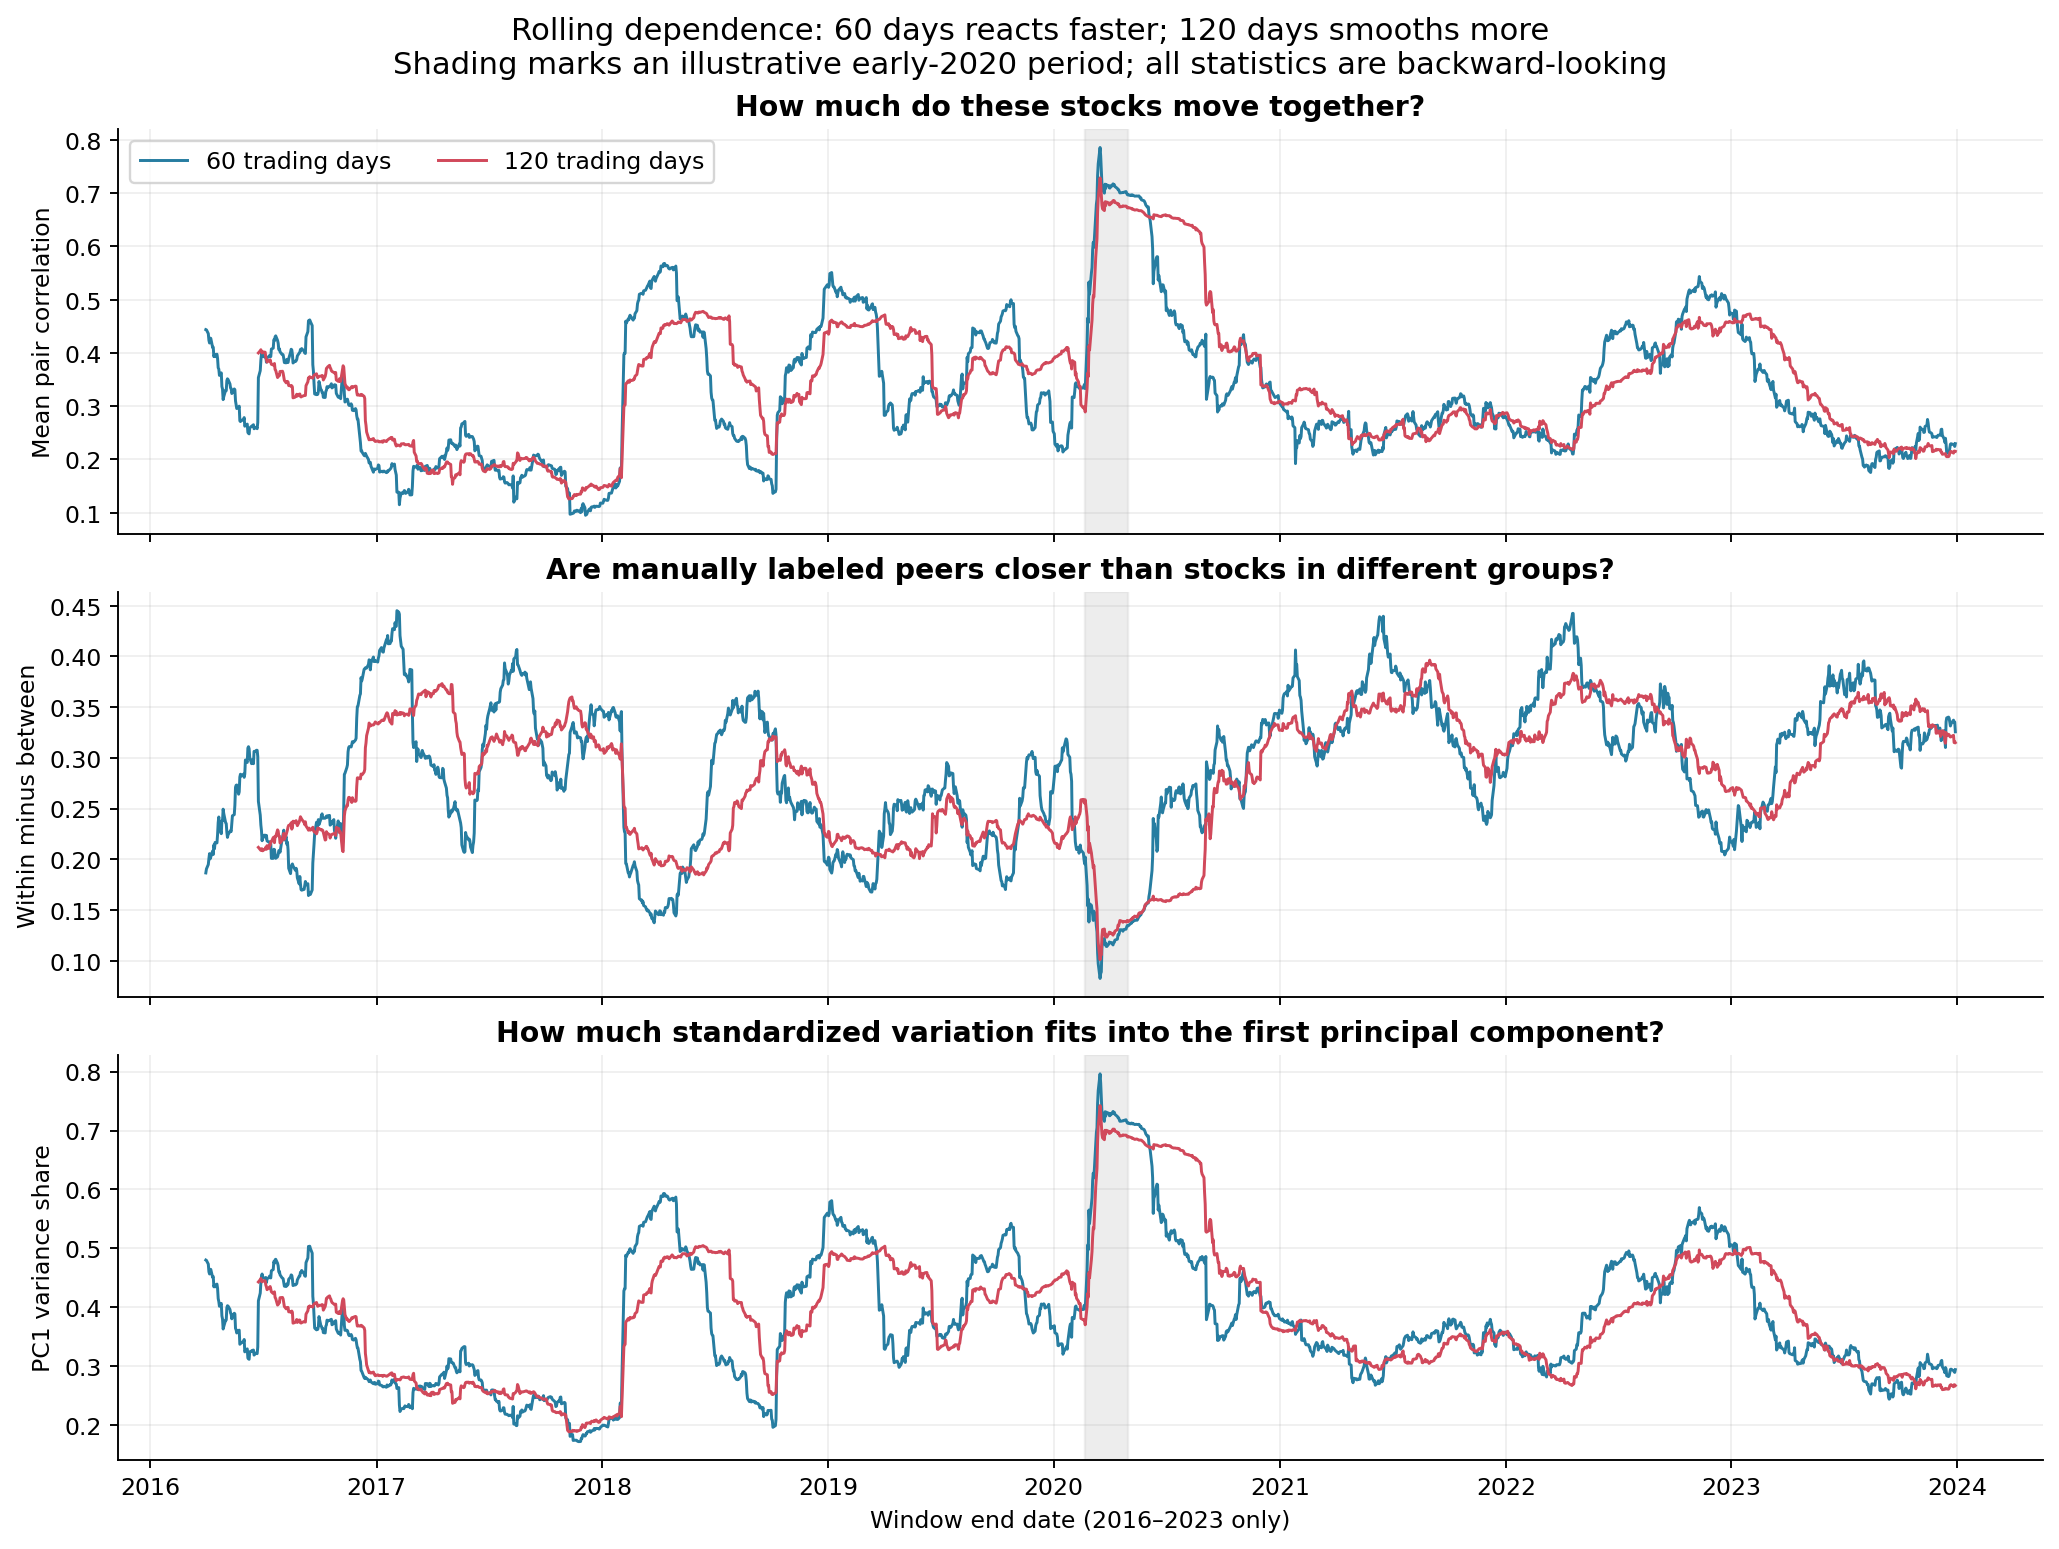

,window,average_correlation,within_group_correlation,between_group_correlation,pc1_variance_share,top3_variance_share,effective_dimension
0,60,0.230,0.511,0.185,0.294,0.515,7.731
1,120,0.215,0.487,0.172,0.267,0.484,8.937


In [2]:
display(Image(filename=str(out / "01_rolling_structure.png")))
latest = pd.DataFrame(summary["latest_rolling"])
cols = ["window", "average_correlation", "within_group_correlation", "between_group_correlation", "pc1_variance_share", "top3_variance_share", "effective_dimension"]
display(latest[cols].round(3))

## 3. Are the bright blocks just the market?

Every heatmap uses the same stock order and color scale. Five-stock group boundaries are marked in black. Red means positively correlated; blue means negatively correlated. The diagonal is always one and is not evidence of a peer relationship.

The lower row regresses each stock on an intercept and SPY over the **same 120-day window**, then correlates the residuals. This removes fitted linear exposure to SPY, not every common economic factor. Remaining relationships can still reflect industries, styles, events, and estimation noise. Removing a common market direction can itself change correlation geometry; negative residual correlations need not imply an economic hedge.

The three dates are illustrative calendar snapshots (year-end 2019, first-quarter-end 2020, and latest development year-end), not dates selected by optimizing a score.

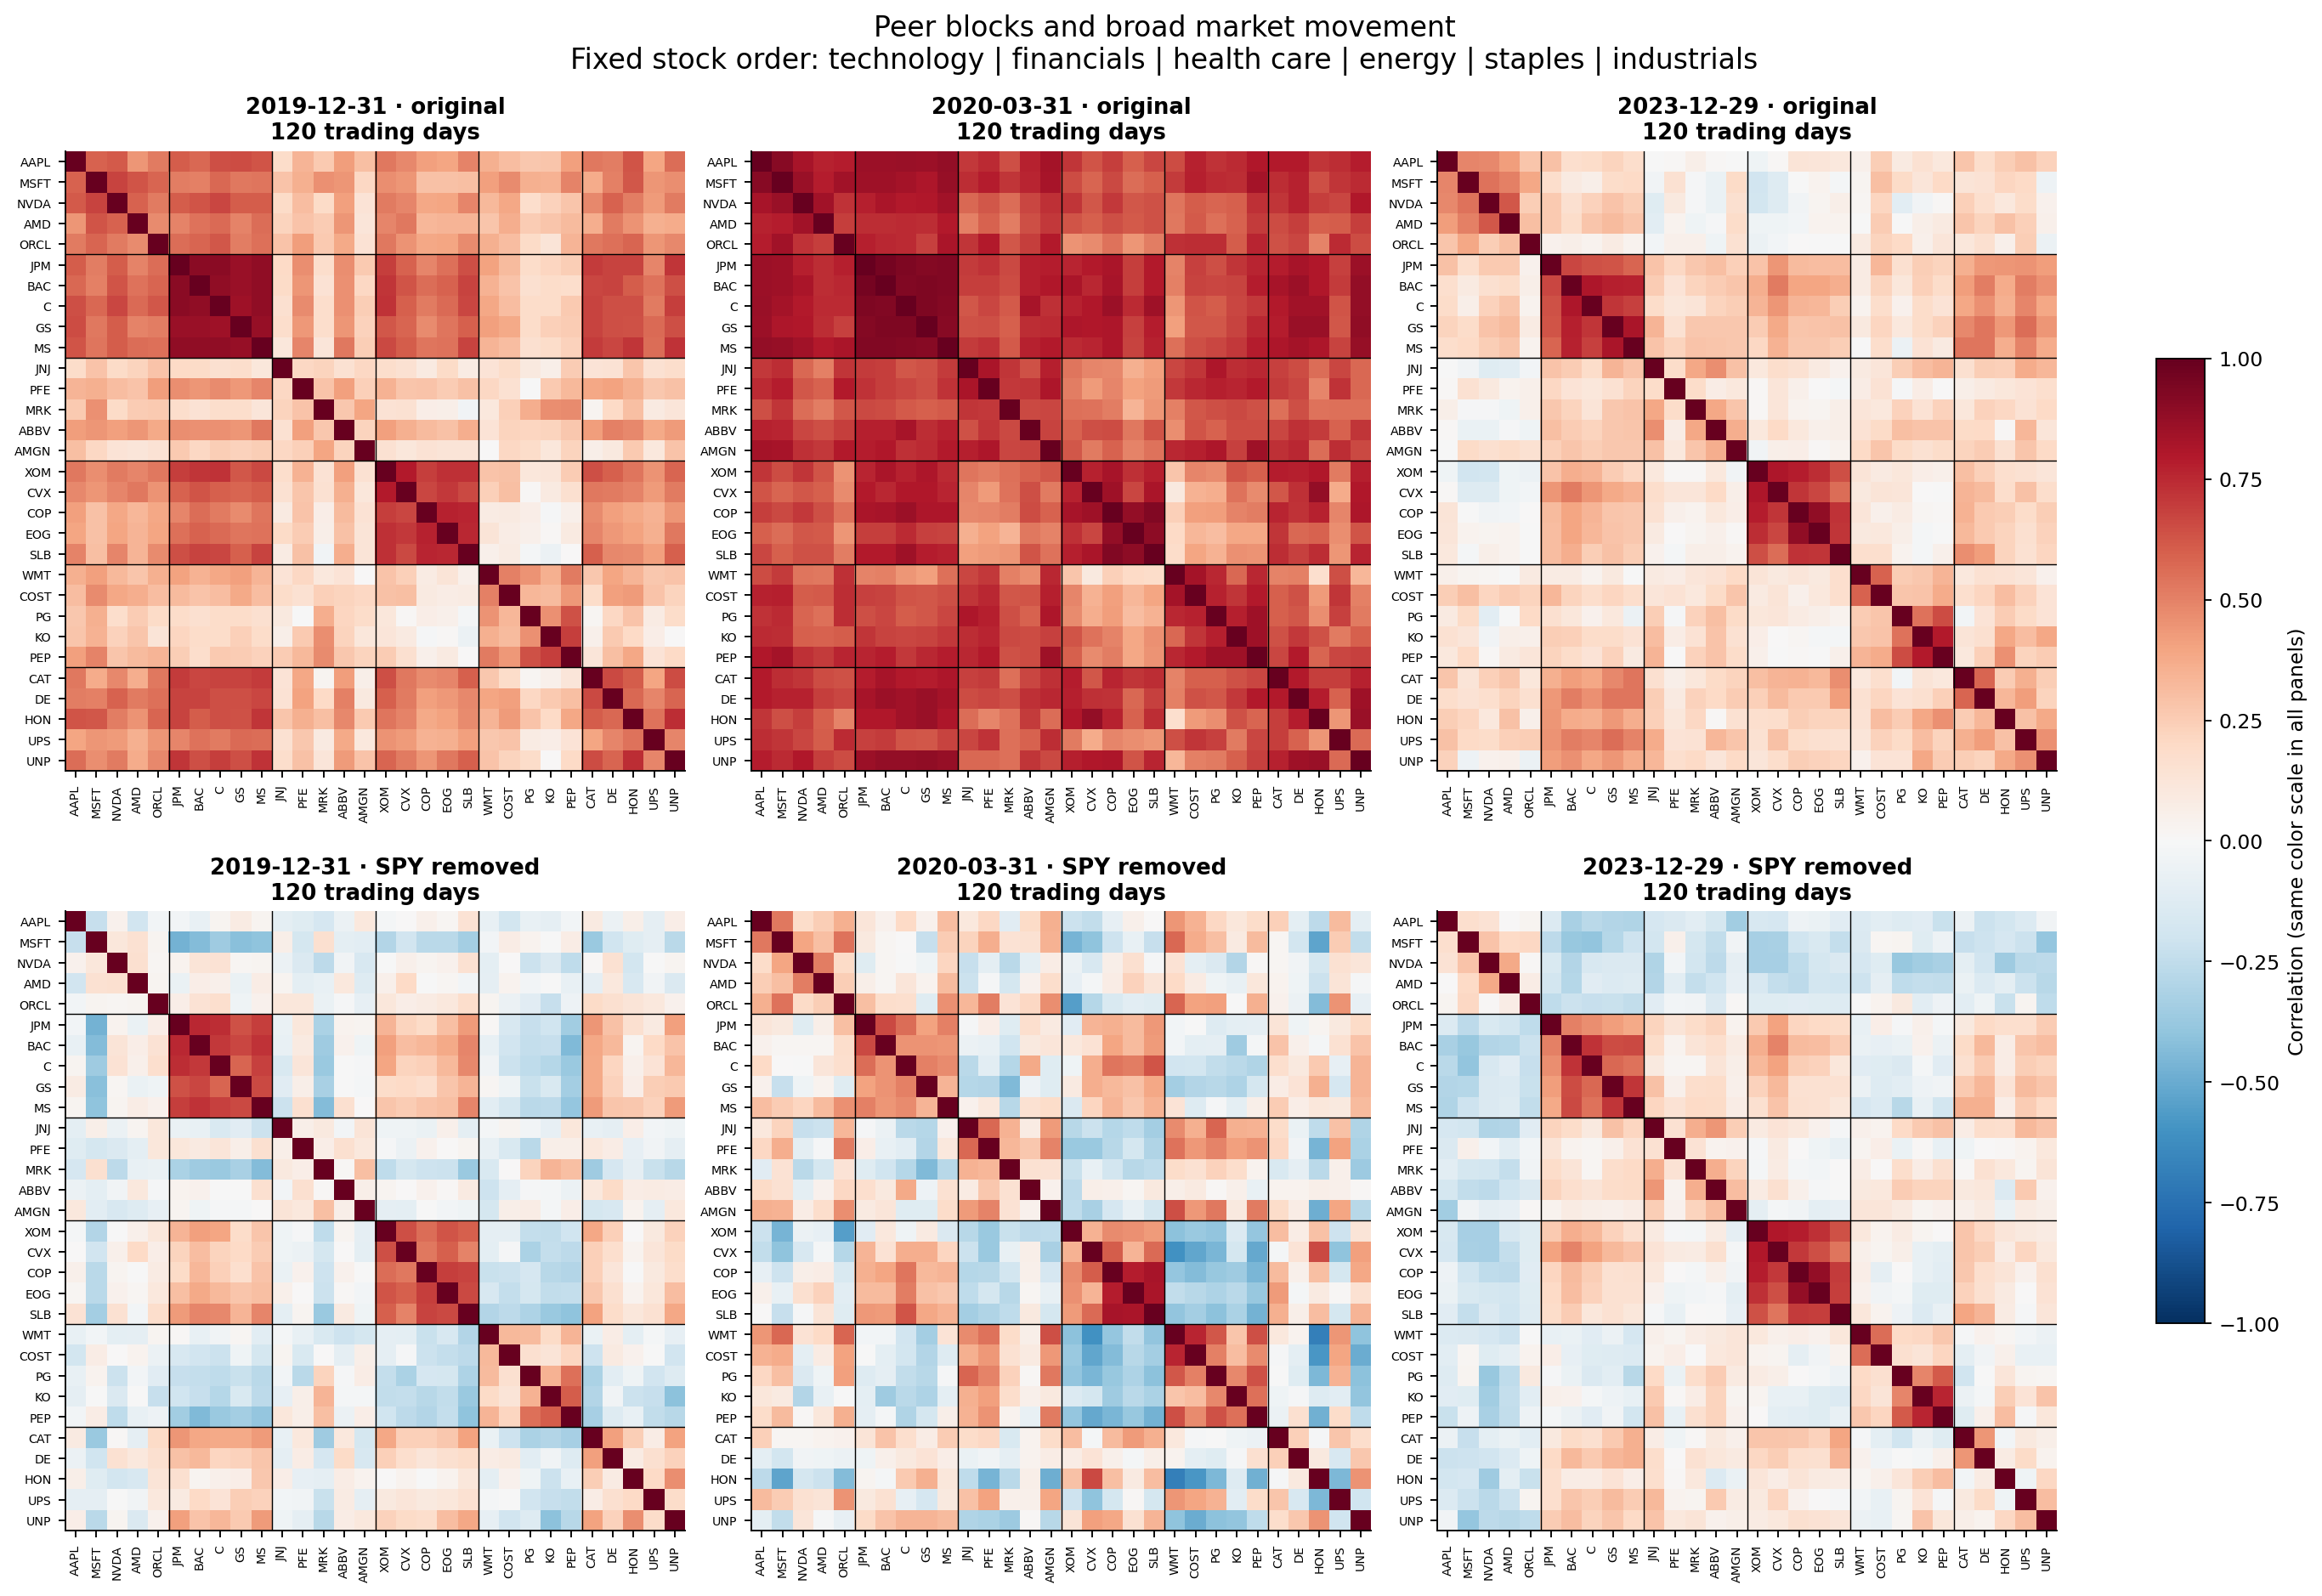

,end_date,start_date,sessions,average_correlation,within_group_correlation,between_group_correlation,pc1_variance_share,market_removed_within,market_removed_between
0,2019-12-31,2019-07-12,120,0.389,0.578,0.358,0.443,0.327,-0.013
1,2020-03-31,2019-10-09,120,0.678,0.789,0.660,0.695,0.379,0.014
2,2023-12-29,2023-07-12,120,0.215,0.487,0.172,0.267,0.359,0.001


In [3]:
display(Image(filename=str(out / "02_correlation_snapshots.png")))
display(pd.DataFrame(summary["snapshots"]).round(3))

## 4. PCA intuition: common movements without named factors

Imagine each day's standardized returns as a point with 30 coordinates. **PC1** is the direction along which this cloud varies most. **PC2** captures the largest remaining variation at a right angle to PC1, and so on. Each day's coordinate along a direction is its **score**. PCA chooses directions from return variation; it is not told which stocks share a sector.

The bar chart shows each component's variance share. The cumulative chart asks how many directions are needed to represent a chosen fraction. The loading heatmap here contains **correlations between stock returns and component scores**, not regression coefficients or directly tradable portfolio weights.

The PC2/PC3 stock map omits PC1 and all higher components. Stocks close on this map share those two loading coordinates, which does not guarantee high overall correlation. A component's sign is arbitrary; near-equal eigenvalues can also allow directions to rotate across windows. A component need not correspond to one named economic factor.

Reference PC1 variance: 43.6%
PC1 score correlation with SPY: 0.928
Components needed for 50% / 80%: 2 / 10


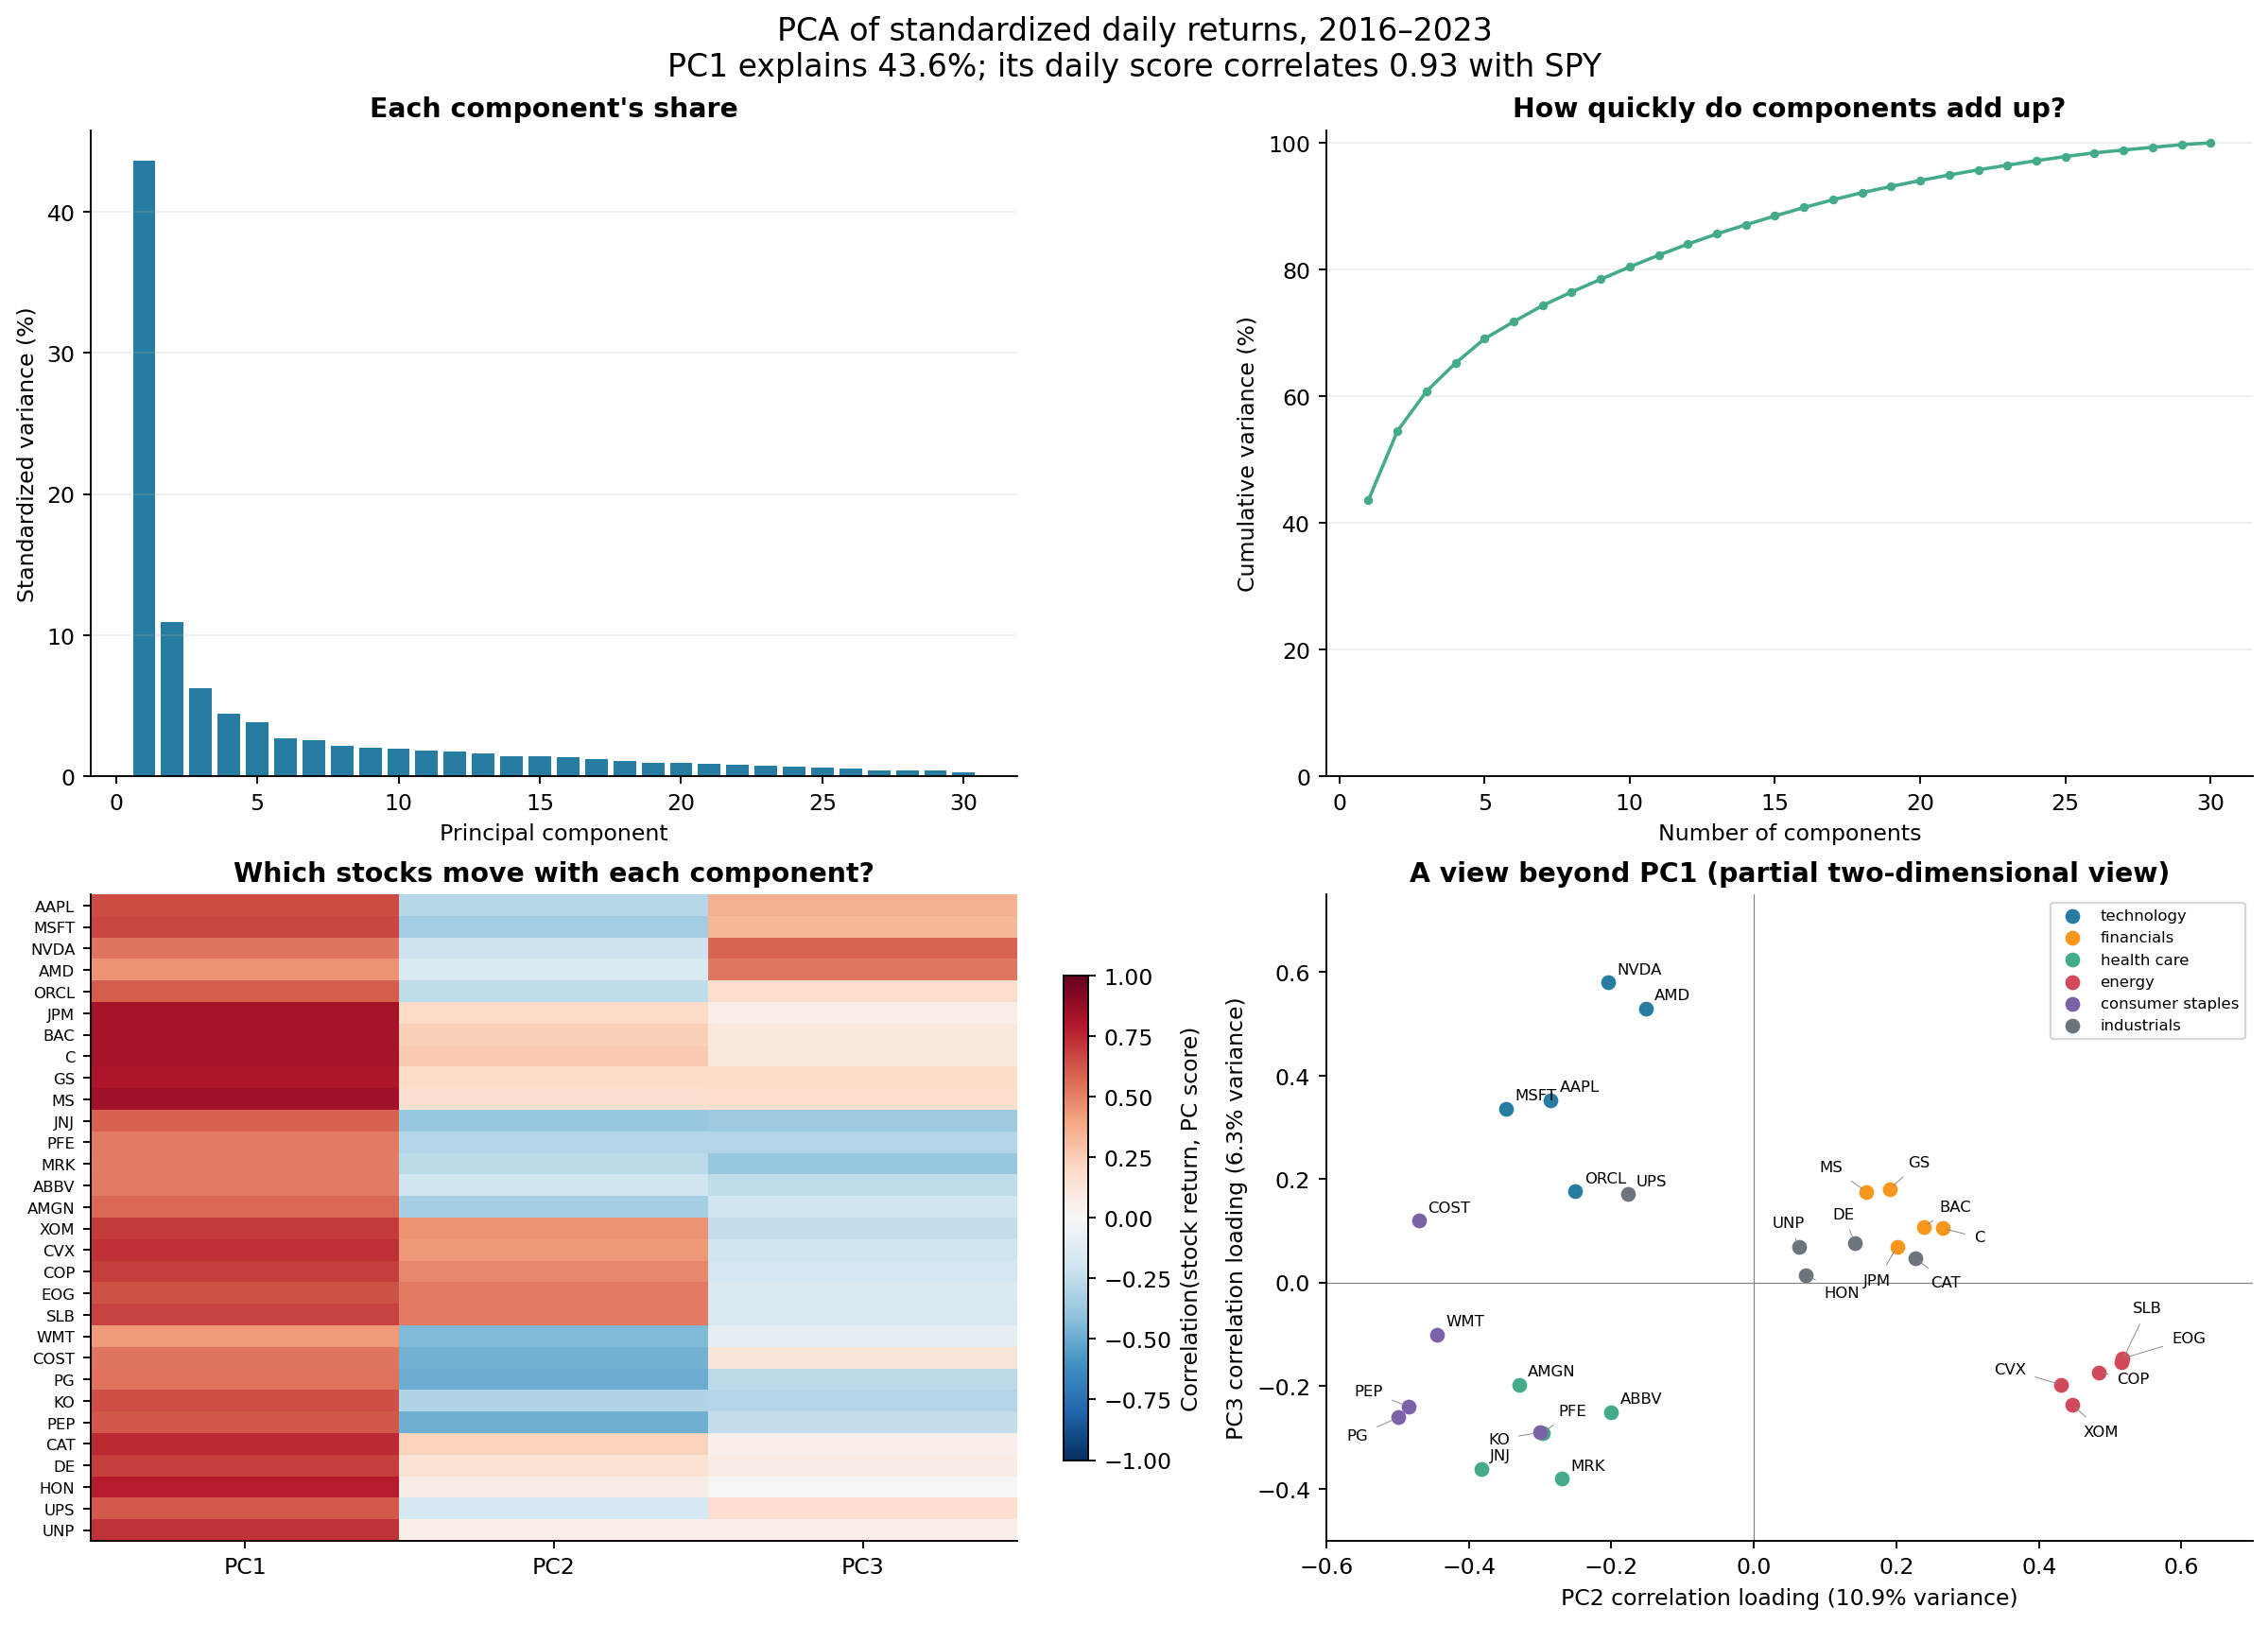

,PC1,PC2,PC3,PC4,PC5
symbol,,,,,
AAPL,0.649,-0.285,0.352,0.180,0.087
MSFT,0.671,-0.348,0.336,0.164,0.109
NVDA,0.535,-0.205,0.580,0.239,0.189
AMD,0.446,-0.152,0.529,0.257,0.234
ORCL,0.609,-0.250,0.176,0.039,0.005
JPM,0.834,0.201,0.069,-0.352,-0.074
BAC,0.821,0.238,0.108,-0.351,-0.064
C,0.821,0.265,0.105,-0.295,-0.047
GS,0.808,0.191,0.181,-0.323,-0.063


In [4]:
display(Image(filename=str(out / "03_pca_intuition.png")))
print(f"Reference PC1 variance: {summary['pca_variance_share'][0]:.1%}")
print(f"PC1 score correlation with SPY: {summary['pc1_spy_correlation']:.3f}")
print(f"Components needed for 50% / 80%: {summary['components_for_50pct']} / {summary['components_for_80pct']}")
loadings = pd.read_csv(out / "pca_stock_component_correlations.csv", index_col="symbol")
display(loadings.round(3))

## 5. A peer hierarchy as a conventional baseline

These trees use `distance = sqrt(2 * (1 - correlation))` and **average linkage**, in the last 120 development sessions. The vertical height is distance, not time. Leaf colors indicate our manual labels; branch colors do not encode inferred groups. Left-to-right leaf order is a visualization choice.

Compare original returns with SPY residuals: do the closest relationships survive the removal of a broad market exposure? The nearest-peer table uses direct pair correlations, not tree proximity.

This is an ordinary clustering baseline. Correlation-derived **H0 persistence corresponds to single linkage**, which is a different linkage rule from the average-linkage tree here. We have not yet computed persistent homology or established a TDA improvement.

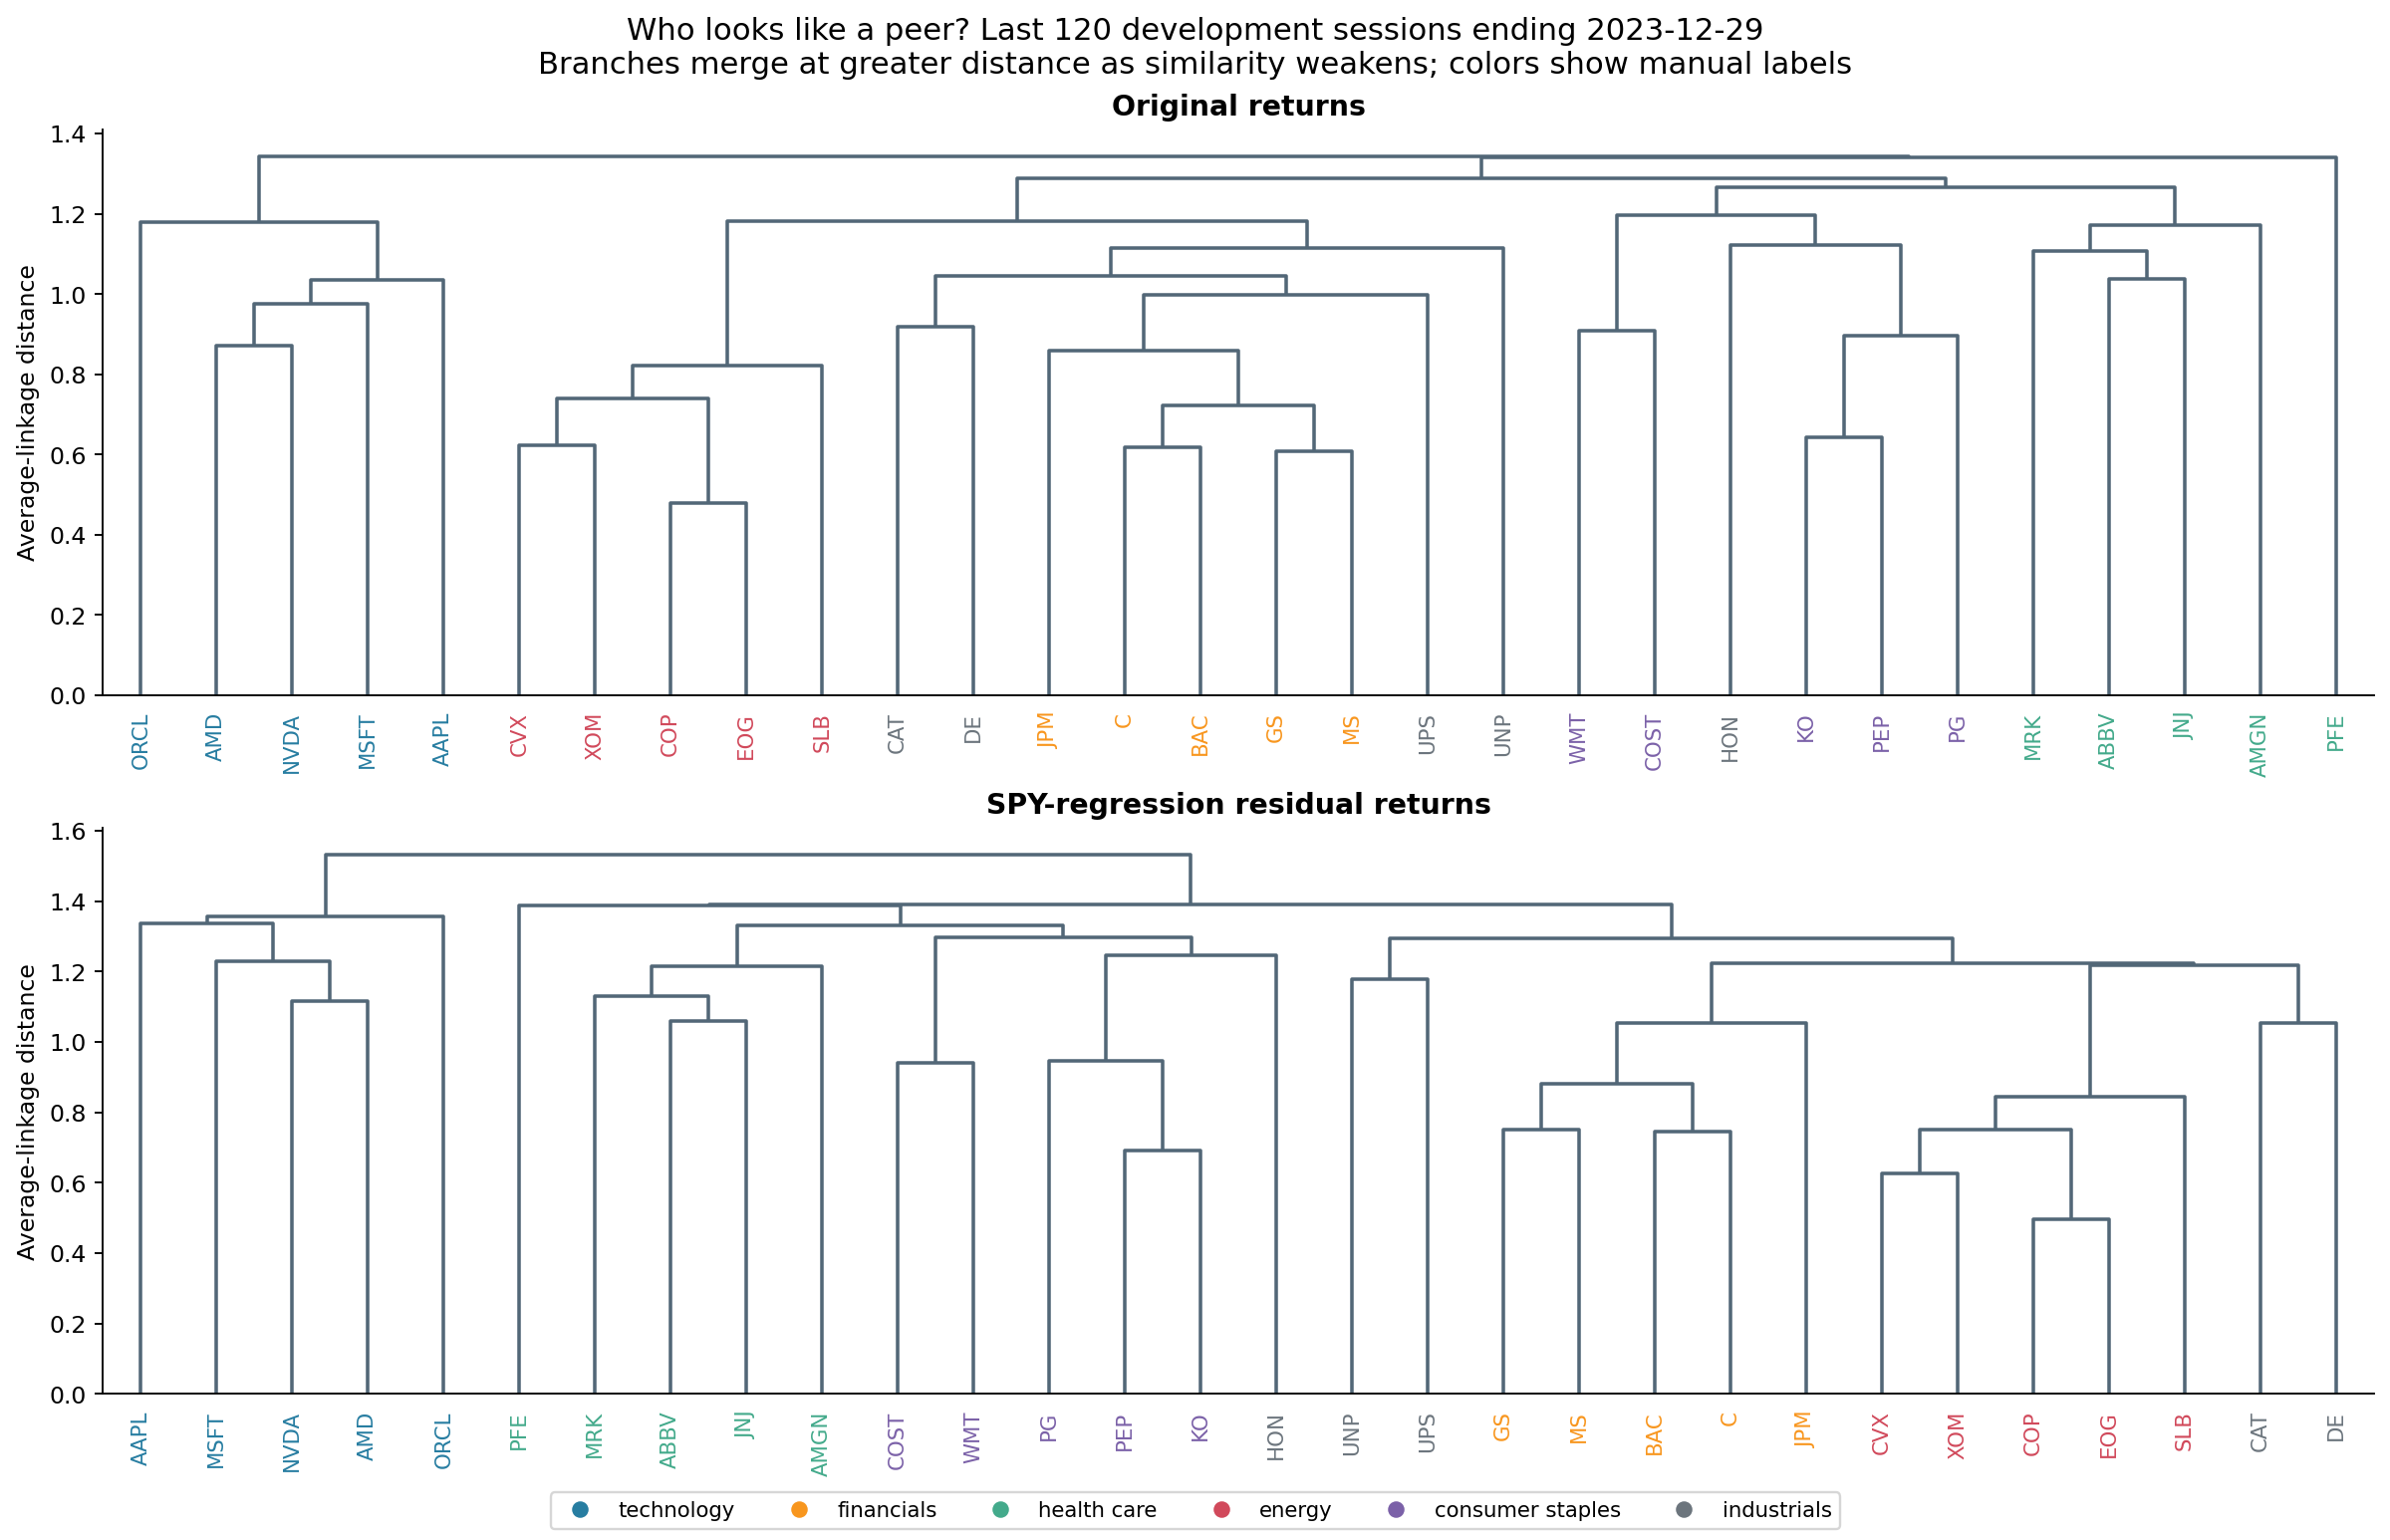

,mode,symbol,manual_group,peer_1,peer_2,peer_3,correlation_1,correlation_2,correlation_3
1,Original returns,MSFT,technology,NVDA,AMD,AAPL,0.543,0.503,0.487
5,Original returns,JPM,financials,BAC,C,GS,0.669,0.639,0.631
15,Original returns,XOM,energy,CVX,COP,EOG,0.806,0.783,0.734
23,Original returns,KO,consumer_staples,PEP,PG,HON,0.794,0.540,0.387
25,Original returns,CAT,industrials,DE,MS,GS,0.579,0.532,0.484
31,SPY-regression residual returns,MSFT,technology,NVDA,ORCL,AMD,0.285,0.206,0.200
35,SPY-regression residual returns,JPM,financials,BAC,C,GS,0.502,0.467,0.421
45,SPY-regression residual returns,XOM,energy,CVX,COP,EOG,0.804,0.783,0.733
53,SPY-regression residual returns,KO,consumer_staples,PEP,PG,UNP,0.760,0.488,0.284
55,SPY-regression residual returns,CAT,industrials,DE,SLB,MS,0.443,0.392,0.352


In [5]:
display(Image(filename=str(out / "04_peer_hierarchies.png")))
peers = pd.read_csv(out / "nearest_peers_2023-12-29.csv")
display(peers.loc[peers.symbol.isin(["MSFT", "JPM", "XOM", "KO", "CAT"])].round(3))

## What this supports, and what comes next

These plots describe changing dependence and compact representations. **High correlation, a large PCA loading, or a clean cluster does not establish future relative-return reversal.** PCA orthogonality is an algebraic property on the fitted sample, not a guarantee of economic independence or low trading risk.

This basket was selected in 2026 and contains surviving companies. Restricting model fits to 2016–2023 does not remove that universe-selection bias. Adjusted prices reflect Alpaca's retrieved corporate-action adjustments and precision; there has been no independent vendor audit. The daily bars have not been verified as regular-session closing-auction prices.

Next, freeze a peer-construction rule on development data, specify the signal and executable timing, and test relative-return reversal separately. Compare manual groups, average linkage, single linkage, and a PCA factor baseline under the same regression. Check stability across dates and windows before introducing more topological summaries. Keep 2024 onward out of tuning.

All generated figures and tables are in `experiments/equity_correlation_pca/`. The adjacent `README.md` records the main findings and definitions. Data remains in `market_data/datasets/equity_daily_30_2016_2026-10-27/`.

The intended cross-sectional contrarian construction is documented in [the verified 151 strategy reference](literature/residual_mean_reversion_151_2026-10-28.md). Use that specification when moving from these diagnostics to a trading experiment.